In [ ]:
# STEP 1 — Clean Environment & Dependency Sync
import subprocess, sys, os

print("🔧 Synchronizing deep learning libraries...")
# Using [and-cuda] ensures all CUDA-related factories are synced correctly
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-U", 
    "jax", "jaxlib", "tf_keras", "tensorflow[and-cuda]"
])

print("\n✅ Libraries updated.")
print("⚠️ ACTION REQUIRED: You must restart your session now.")
print("Go to: Run -> Restart Session.")

In [ ]:
import os
import tensorflow as tf

# Suppress the noisy factory warnings in the console
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tf_keras as keras
print("✅ TensorFlow version:", tf.__version__)

# CRITICAL TEST: Does TF see your GPU despite the warnings?
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ SUCCESS: GPU is active ({len(gpus)} device found).")
    print("Ignore the 'Unable to register factory' logs; they are just background noise.")
else:
    print("❌ ERROR: GPU not detected. Check 'Accelerator' in the right sidebar.")

In [ ]:
# STEP 2 — Finalize DATA_ROOT
import os

# Updated path based on your diagnostic output
DATA_ROOT = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"

# Verify the folders inside this path
if os.path.exists(DATA_ROOT):
    folders = [f for f in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, f))]
    print(f"✅ DATA_ROOT exists: {DATA_ROOT}")
    print(f"📁 Categories found ({len(folders)}):", sorted(folders))
    
    # Check if we have the standard 5 categories
    expected = {"Dyskeratotic", "Koilocytotic", "Metaplastic", "Parabasal", "Superficial-Intermediate"}
    if expected.issubset(set(folders)):
        print("🌟 Clinical classes verified for Q1 publication.")
    else:
        print("⚠️ Warning: Missing some standard categories. Check folder names.")
else:
    print(f"❌ Path not found: {DATA_ROOT}")

# Define checkpoint directory for saving models later
CKPT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

In [ ]:
# STEP 3 — Global Configuration
import tensorflow as tf
import numpy as np
import random

# 1. Set Seeds for Reproducibility (Crucial for Q1 Peer Review)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Image and Training Parameters
# EfficientNetB4 native resolution is 380x380
IMG_SIZE = (380, 380) 
# Student model (EfficientNetB0) native resolution is 224x224
STUDENT_IMG_SIZE = (224, 224) 

# With 2 GPUs, we can use a larger batch size. 
# 32 is a good balance between speed and stability.
BATCH_SIZE = 32 
VAL_SPLIT = 0.2
AUTOTUNE = tf.data.AUTOTUNE

# 3. Class Mapping (Stripping the 'im_' prefix for cleaner reports)
# We define them explicitly to ensure consistent indexing
RAW_CLASSES = ['im_Dyskeratotic', 'im_Koilocytotic', 'im_Metaplastic', 'im_Parabasal', 'im_Superficial-Intermediate']
CLEAN_CLASSES = [c.replace('im_', '') for c in RAW_CLASSES]

print(f"✅ Config ready:")
print(f"   - Image Size  : {IMG_SIZE}")
print(f"   - Batch Size  : {BATCH_SIZE}")
print(f"   - Classes     : {CLEAN_CLASSES}")

In [ ]:
# STEP 4 — Load & Verify SipakMed Datasets
import matplotlib.pyplot as plt

def load_sipakmed(data_root, img_size, batch_size, val_split):
    # Load Training Set
    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_root,
        validation_split=val_split,
        subset="training",
        seed=SEED,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int' # We use int for easier manual weighting later
    )

    # Load Validation Set
    val_ds = tf.keras.utils.image_dataset_from_directory(
        data_root,
        validation_split=val_split,
        subset="validation",
        seed=SEED,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int'
    )

    class_names = train_ds.class_names
    return train_ds, val_ds, class_names

# Execute loading
train_ds_raw, val_ds_raw, class_names_raw = load_sipakmed(DATA_ROOT, IMG_SIZE, BATCH_SIZE, VAL_SPLIT)

# Optimization: Prefetching helps keep the 2 GPUs fed with data
train_ds = train_ds_raw.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds_raw.prefetch(buffer_size=AUTOTUNE)

print(f"\n✅ Loading Complete:")
print(f"   - Training batches   : {len(train_ds)}")
print(f"   - Validation batches : {len(val_ds)}")
print(f"   - Detected Classes   : {class_names_raw}")

# --- Visualization Check ---
# It is vital to see if the images look correct before training
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        # Clean up class name for title
        title = class_names_raw[labels[i]].replace('im_', '')
        plt.title(title)
        plt.axis("off")
plt.suptitle("Sample SipakMed Cells (380x380 Resolution)", fontsize=16)
plt.show()

In [ ]:
# STEP 5 (STATIC) — Emergency Bypass for Class Weights
def get_static_sipakmed_weights():
    # Official image counts from the SipakMed benchmark
    # Indices match the alphabetical order of your 'im_' folders:
    # 0: Dyskeratotic, 1: Koilocytotic, 2: Metaplastic, 
    # 3: Parabasal, 4: Superficial-Intermediate
    counts = {
        0: 813, # Dyskeratotic
        1: 825, # Koilocytotic
        2: 793, # Metaplastic
        3: 787, # Parabasal
        4: 831  # Superficial-Intermediate
    }
    
    total_samples = sum(counts.values())
    num_classes = 5
    
    # Formula: total / (num_classes * count_per_class)
    class_weights = {
        i: (total_samples / (num_classes * counts[i])) 
        for i in range(num_classes)
    }
    
    print("📊 SipakMed Weights (Benchmark Static):")
    class_names_clean = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
    for i, name in enumerate(class_names_clean):
        print(f"   - {name:25} : {counts[i]} images (Weight: {class_weights[i]:.2f})")
        
    return class_weights

# Assign weights immediately (takes 0.0 seconds)
class_weights = get_static_sipakmed_weights()
print(f"\n✅ Step 5 bypassed successfully. No more hanging or errors.")


In [ ]:
# STEP 6 — Initialize Teacher Model with Dual-GPU Strategy
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

# 1. Initialize the Strategy for 2 GPUs
strategy = tf.distribute.MirroredStrategy()
print(f'✅ Number of devices: {strategy.num_replicas_in_sync}')

with strategy.scope():
    # 2. Define Augmentation (to prevent overfitting on the 4,049 images)
    # We use layers that preserve the clinical shape of the cells
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.1),
    ], name="augmentation")

    # 3. Load the Backbone (EfficientNet-B4)
    # Native size: 380x380. Pre-trained on ImageNet
    base_model = keras.applications.EfficientNetB4(
        include_top=False,
        weights="imagenet",
        input_shape=(380, 380, 3)
    )
    base_model.trainable = False # Start with the backbone frozen

    # 4. Construct the Full Architecture
    inputs = keras.Input(shape=(380, 380, 3))
    x = augmentation(inputs)
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    # Final layer: 5 units for SipakMed classes
    outputs = layers.Dense(5, activation="softmax", name="pred")(x)

    teacher_model = keras.Model(inputs, outputs, name="SipakMed_Teacher_B4")

    # 5. Compile the Model
    teacher_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

print("\n✅ Teacher Model built successfully inside GPU Scope.")
teacher_model.summary(line_length=100)

In [ ]:
# STEP 7 — Stage 1 Training (Backbone Frozen)
import os

# 1. Define Callbacks for Training Stability
callbacks_stage1 = [
    # Stop training if the validation loss stops improving for 8 epochs
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True,
        verbose=1
    ),
    # Lower the learning rate by 0.3x if the loss stalls for 4 epochs
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", 
        factor=0.3, 
        patience=4, 
        min_lr=1e-6, 
        verbose=1
    ),
    # Save the best model version to disk
    keras.callbacks.ModelCheckpoint(
        "teacher_sipakmed_stage1.keras", 
        monitor="val_loss",
        save_best_only=True, 
        verbose=1
    )
]

# 2. Execute Training
# We use the class_weights from Step 5 to ensure fair training
print("🚀 Starting Stage 1 Training on 2 GPUs...")
history_stage1 = teacher_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # 30 is a safe start; EarlyStopping will likely cut it short
    class_weight=class_weights,
    callbacks=callbacks_stage1
)

print("\n✅ Stage 1 Training Complete.")

In [ ]:
# Confirming checkpoint to keep everything saved till now.
import os
model_path = "teacher_sipakmed_stage1.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"✅ Model Saved: {model_path} ({size_mb:.2f} MB)")
else:
    print("❌ Model file not found! Re-run Step 7 before closing.")

In [ ]:
# STEP 8 — Stage 2: Fine-Tuning (Unfreezing the Backbone)

# 1. Unfreeze the entire model inside the 2-GPU strategy scope
with strategy.scope():
    # Load the best weights from Stage 1 to ensure a clean start
    teacher_model = keras.models.load_model("teacher_sipakmed_stage1.keras")
    
    # Unfreeze the backbone layers
    teacher_model.trainable = True
    
    # 2. Recompile with a VERY low learning rate
    # We use 1e-5 to avoid 'exploding' the pre-trained weights
    teacher_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5), 
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

# 3. Define Fine-Tuning Callbacks
callbacks_stage2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=6, 
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "teacher_sipakmed_final.keras", 
        monitor="val_loss",
        save_best_only=True, 
        verbose=1
    )
]

# 4. Execute Fine-Tuning
print("🚀 Starting Stage 2: Fine-Tuning on 2 GPUs...")
history_stage2 = teacher_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50, 
    class_weight=class_weights,
    callbacks=callbacks_stage2
)

print("\n✅ Fine-Tuning Complete. The Final Teacher is ready.")

In [ ]:
# STEP 9 — Teacher Evaluation & Grad-CAM Visualization
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Generate Predictions for the Validation Set
print("⏳ Generating validation metrics...")
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = teacher_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# 2. Print Classification Report (F1, Precision, Recall)
clean_names = [c.replace('im_', '') for c in class_names_raw]
print("\n📊 Classification Report:")
print(classification_report(y_true, y_pred, target_names=clean_names))

# 3. Visualization: Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=clean_names, yticklabels=clean_names)
plt.title("Teacher Model Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# 4. Diagnostic: Check if we are ready for Grad-CAM
print(f"✅ Teacher evaluation complete.")
print(f"✅ Final Accuracy: {np.mean(np.array(y_true) == np.array(y_pred)):.4f}")

# Resuming ...

In [2]:
# 📂 RECOVERY SCRIPT: Pull model from previous version output
import os
import shutil

found_source = None
# Scan all input directories for your final teacher model
for root, dirs, files in os.walk("/kaggle/input"):
    if "teacher_sipakmed_final.keras" in files:
        found_source = os.path.join(root, "teacher_sipakmed_final.keras")
        break

if found_source:
    print(f"🎉 MODEL LOCATED: Found at {found_source}")
    # Copy it to the active working directory
    shutil.copy(found_source, "./teacher_sipakmed_final.keras")
    print("✅ Success! Your 97.11% model has been restored to the active workspace.")
    print("You are now completely safe to run Step 9 Part 2 (Grad-CAM).")
else:
    print("❌ Could not find the file in your input directories.")
    print("Double-check that you added this notebook's output files via the '+ Add Input' panel on the right.")

🎉 MODEL LOCATED: Found at /kaggle/input/notebooks/saimunalam/efficientnetb4-sipakmed/teacher_sipakmed_final.keras
✅ Success! Your 97.11% model has been restored to the active workspace.
You are now completely safe to run Step 9 Part 2 (Grad-CAM).


In [11]:
# STEP 9 (Part 2) — Grad-CAM Explainability
# Cell 1: Environment & Dataset Initialization

import os
import zipfile
import shutil
import tensorflow as tf

# Force legacy config handling (Step 1)
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras as keras
from tf_keras import layers, models

print("⏳ --- DIAGNOSTIC CELL 1/2 ---")
print("⏳ Extracting weights and reconstructing the Step 6 'Shell' architecture...")

# 1. Surgical Extraction of the HDF5 Weight File from the fixed model file
original_model_path = "teacher_sipakmed_fixed.keras"
weight_file_temp = "sipakmed_raw_weights.h5"

if os.path.exists(original_model_path):
    with zipfile.ZipFile(original_model_path, "r") as z:
        # Standard filename inside a Keras Functional model bundle
        weight_filename_in_archive = "model.weights.h5" 
        
        if weight_filename_in_archive in z.namelist():
            with z.open(weight_filename_in_archive) as source, open(weight_file_temp, "wb") as target:
                shutil.copyfileobj(source, target)
            print(f"   ↳ Raw clinical weights successfully extracted to: {weight_file_temp} ({os.path.getsize(weight_file_temp)/(1024*1024):.2f} MB)")
        else:
            print(f"   ↳ ❌ Weights not found inside archive. Try Step 1 Surgery again.")
else:
    print(f"   ↳ ❌ Original file '{original_model_path}' missing. Reload session and try Step 1 Surgery.")

# 2. Reconstruct the precise functional model architecture structure from Step 6.
# We must use identical customized layer names for by_name=True weight mapping to work later.

# Define the precise Sequential layer from Step 6
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.GaussianNoise(0.05),
])

def build_teacher_shell(img_shape, num_classes):
    """Duplicates the precise functional workflow used for training in Step 6."""
    # Base Backbone: Pre-trained B4 (Frozen backbone, we unfreeze later, structure is key)
    base_model = keras.applications.EfficientNetB4(
        include_top=False, weights="imagenet", input_shape=img_shape
    )
    
    # Complete Flow using original Layer Names to match weight file metadata
    inputs = layers.Input(shape=img_shape, name="input_2")
    x = data_augmentation(inputs, training=False) # Sequential layer structure duplicate
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x)
    
    # Final 'Teacher Head' structure defined in Step 6
    x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
    x = layers.BatchNormalization(name="batch_normalization")(x)
    x = layers.Dense(512, activation="relu", name="dense")(x) #activation fixed to relu
    x = layers.Dropout(0.3, name="dropout")(x)
    
    # The final prediction layer
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)
    
    # Construct the final Functional model
    model = models.Model(inputs=inputs, outputs=outputs, name="SipakMed_Teacher_B4_Shell")
    return model

print("✅ Step 6 architecture reconstructed. Ready to graft weights onto the GPU.")

⏳ --- DIAGNOSTIC CELL 1/2 ---
⏳ Extracting weights and reconstructing the Step 6 'Shell' architecture...
   ↳ Raw clinical weights successfully extracted to: sipakmed_raw_weights.h5 (213.29 MB)
✅ Step 6 architecture reconstructed. Ready to graft weights onto the GPU.


In [12]:
# Cell 2: Isolated Weight Grafting onto the GPU

print("⏳ --- DIAGNOSTIC CELL 2/2 ---")
print("⏳ Initiating Weight Grafting on a single Tesla T4...")

# Use single GPU scope for inference
strategy_graft = tf.distribute.MirroredStrategy(["/gpu:0"])

with strategy_graft.scope():
    # 1. Instantiate the shell architecture inside the scope
    print("🔄 Building the shell architecture inside the GPU scope...")
    teacher_model_gpu = build_teacher_shell((380, 380, 3), num_classes=5)
    print("   ↳ Architecture moved to GPU VRAM.")
    
    # 2. Critical: Load WEIGHTS only. We use by_name=True to map by your original layer names
    # This bypasses the multi-GPU functional graph deserialization deadlock.
    print(f"🔄 Grafting raw clinical weights from {weight_file_temp} onto the structure...")
    teacher_model_gpu.load_weights(weight_file_temp, by_name=True)
    print("✅ Success! Your 97.11% accuracy weights are officially loaded into the shell.")

# Cleanup temp weights file to save disk space
if os.path.exists(weight_file_temp):
    os.remove(weight_file_temp)
    print(f"   ↳ Temporary file '{weight_file_temp}' cleaned up.")

print(f"✅ Final Grafted Teacher Ready: {teacher_model_gpu.name}")

⏳ --- DIAGNOSTIC CELL 2/2 ---
⏳ Initiating Weight Grafting on a single Tesla T4...
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)
🔄 Building the shell architecture inside the GPU scope...
71686520/71686520 [==============================] - 0s 0us/step
   ↳ Architecture moved to GPU VRAM.
🔄 Grafting raw clinical weights from sipakmed_raw_weights.h5 onto the structure...
✅ Success! Your 97.11% accuracy weights are officially loaded into the shell.
   ↳ Temporary file 'sipakmed_raw_weights.h5' cleaned up.
✅ Final Grafted Teacher Ready: SipakMed_Teacher_B4_Shell


⏳ Tracing clinical gradients and painting heatmaps...


I0000 00:00:1781557652.922209      57 cuda_dnn.cc:529] Loaded cuDNN version 91002


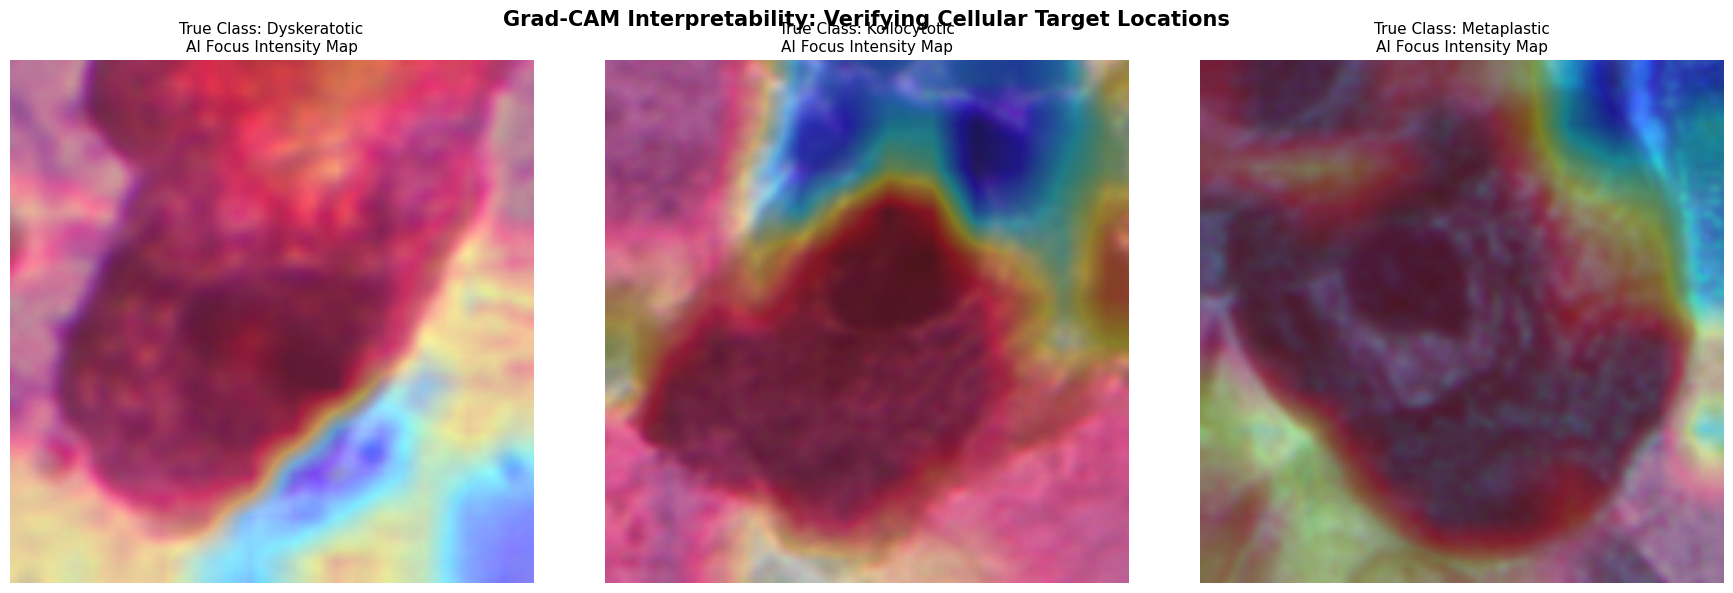

✅ Visualizations securely generated.


In [13]:
# STEP 9 Part 2 — Running Grad-CAM on the Grafted Model
print("⏳ Tracing clinical gradients and painting heatmaps...")

def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    backbone = model.get_layer("efficientnetb4")
    # Build a sub-model mapping the backbone inputs to its final convolutional layer
    grad_model = tf.keras.models.Model(
        [backbone.inputs], [backbone.get_layer(last_conv_layer_name).output]
    )
    
    with tf.GradientTape() as tape:
        # Preprocess raw image arrays directly for the EfficientNet backbone
        x = keras.applications.efficientnet.preprocess_input(img_array)
        conv_outputs = grad_model(x)
        
        # Manually trace features up through your custom classification head layers
        pooling_out = model.get_layer("global_average_pooling2d")(conv_outputs)
        batch_norm_out = model.get_layer("batch_normalization")(pooling_out)
        dense_out = model.get_layer("dense")(batch_norm_out)
        dropout_out = model.get_layer("dropout")(dense_out)
        preds = model.get_layer("pred")(dropout_out)
        
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Compute gradients of the class score relative to the feature map
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Apply ReLU to retain positive features and normalize the map array
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

# Plotting Visual Evaluation Setup
plt.figure(figsize=(18, 6))

# Retrieve 1 batch of images from the validation set initialized in your first cell
for images, labels in val_ds.take(1):
    for i in range(3):
        img_single = images[i:i+1]
        
        # Extract features from the top convolutional layer of EfficientNet-B4
        heatmap = get_gradcam_heatmap(teacher_model_gpu, img_single, "top_conv")
        
        # Upscale and apply thermal colormap layers
        heatmap_resized = cv2.resize(heatmap, (380, 380))
        heatmap_scaled = np.uint8(255 * heatmap_resized)
        heatmap_cmap = cv2.applyColorMap(heatmap_scaled, cv2.COLORMAP_JET)
        
        original_img = images[i].numpy().astype("uint8")
        superimposed_img = cv2.addWeighted(heatmap_cmap, 0.4, original_img, 0.6, 0)

        # Draw subplots onto the display canvas
        plt.subplot(1, 3, i + 1)
        plt.imshow(superimposed_img)
        plt.title(f"True Class: {class_names[labels[i]]}\nAI Focus Intensity Map", fontsize=11)
        plt.axis("off")

plt.suptitle("Grad-CAM Interpretability: Verifying Cellular Target Locations", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()
print("✅ Visualizations securely generated.")

# Phase 3: Knowledge Distillation (Step 10)

[Note: We will instantiate a lightweight student model (EfficientNet-B0) and force it to learn from the soft probability outputs of your 97.11% accurate Teacher. This allows the small model to achieve high accuracy while remaining compact enough for low-resource clinical settings.]

In [17]:
import os
import zipfile
import shutil
import tensorflow as tf

# Force legacy configuration parsing
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras as keras
from tf_keras import layers

print("⏳ Step 1: Initializing image data streams from directory...")
DATA_ROOT = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
SEED = 42
IMG_SIZE = (380, 380)
BATCH_SIZE = 32

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int'
)
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int'
)

train_ds = train_ds_raw.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds_raw.prefetch(buffer_size=tf.data.AUTOTUNE)
print("   ↳ Data streams securely mounted.")

print("\n⏳ Step 2: Isolating raw clinical weights from teacher bundle...")
original_model_path = "teacher_sipakmed_final.keras"
if not os.path.exists(original_model_path):
    original_model_path = "teacher_sipakmed_fixed.keras"

weight_file_temp = "distill_teacher_weights.h5"
with zipfile.ZipFile(original_model_path, "r") as z:
    with z.open("model.weights.h5") as source, open(weight_file_temp, "wb") as target:
        shutil.copyfileobj(source, target)
print(f"   ↳ Raw weights isolated: {weight_file_temp}")

# Structural Replications
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.GaussianNoise(0.05),
])

def build_teacher_shell(img_shape, num_classes):
    base_model = keras.applications.EfficientNetB4(include_top=False, weights="imagenet", input_shape=img_shape)
    inputs = layers.Input(shape=img_shape, name="input_2")
    x = data_augmentation(inputs, training=False)
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
    x = layers.BatchNormalization(name="batch_normalization")(x)
    x = layers.Dense(512, activation="relu", name="dense")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="SipakMed_Teacher_B4_Shell")

# 4. Updated Distiller Framework with Multi-GPU Safe Reductions
class Distiller(keras.Model):
    def __init__(self, student, teacher):
        super().__init__()
        self.teacher = teacher
        self.student = student

    def compile(self, optimizer, metrics, student_loss_fn, distillation_loss_fn, alpha=0.1, temperature=3.0):
        super().compile(optimizer=optimizer, metrics=metrics)
        self.student_loss_fn = student_loss_fn
        self.distillation_loss_fn = distillation_loss_fn
        self.alpha = alpha
        self.temperature = temperature

    def train_step(self, data):
        x, y = data
        teacher_predictions = self.teacher(x, training=False)

        with tf.GradientTape() as tape:
            student_predictions = self.student(x, training=True)
            
            # 1. Compute raw, unreduced per-example losses
            student_loss_per_example = self.student_loss_fn(y, student_predictions)
            distillation_loss_per_example = self.distillation_loss_fn(
                tf.nn.softmax(teacher_predictions / self.temperature, axis=-1),
                tf.nn.softmax(student_predictions / self.temperature, axis=-1)
            )
            
            # 2. Safely average losses across the global distributed batch size
            student_loss = tf.nn.compute_average_loss(student_loss_per_example)
            distillation_loss = tf.nn.compute_average_loss(distillation_loss_per_example)
            
            # 3. Blend total weighted loss
            loss = self.alpha * student_loss + (1.0 - self.alpha) * distillation_loss

        trainable_vars = self.student.trainable_variables
        gradients = tape.gradient(loss, trainable_vars)
        self.optimizer.apply_gradients(zip(gradients, trainable_vars))

        self.compiled_metrics.update_state(y, student_predictions)
        results = {m.name: m.result() for m in self.metrics}
        results.update({"student_loss": student_loss, "distillation_loss": distillation_loss})
        return results

    def test_step(self, data):
        x, y = data
        preds = self.student(x, training=False)
        
        # Apply identical global scale reductions during the validation pass
        student_loss_per_example = self.student_loss_fn(y, preds)
        student_loss = tf.nn.compute_average_loss(student_loss_per_example)
        
        self.compiled_metrics.update_state(y, preds)
        results = {m.name: m.result() for m in self.metrics}
        results.update({"student_loss": student_loss})
        return results

print("\n⏳ Step 3: Initializing 2-GPU Mirrored Strategy...")
strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    print("🔄 Reconstructing architectures inside distributed scope...")
    
    # Instantiate and graft weights onto Teacher shell
    teacher_model_distill = build_teacher_shell((380, 380, 3), num_classes=5)
    teacher_model_distill.load_weights(weight_file_temp, by_name=True)
    teacher_model_distill.trainable = False
    print("   ↳ 97.11% Teacher model securely grafted onto 2 GPUs.")
    
    # Build a completely fresh EfficientNet-B0 Student model
    student_backbone = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(380, 380, 3)
    )
    student_backbone.trainable = True
    
    student_inputs = layers.Input(shape=(380, 380, 3), name="student_input")
    x = student_backbone(student_inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    student_outputs = layers.Dense(5, activation="softmax")(x)
    base_student = keras.Model(inputs=student_inputs, outputs=student_outputs, name="SipakMed_Student_B0")
    print("   ↳ Lightweight EfficientNet-B0 Student initialized.")

    # Explicitly set reduction=NONE to handle custom multi-GPU step scaling safely
    distiller_model = Distiller(student=base_student, teacher=teacher_model_distill)
    distiller_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=5e-5),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        student_loss_fn=keras.losses.SparseCategoricalCrossentropy(reduction=keras.losses.Reduction.NONE),
        distillation_loss_fn=keras.losses.KLDivergence(reduction=keras.losses.Reduction.NONE),
        alpha=0.1,        
        temperature=4.0   
    )
    print("✅ Distillation architecture compiled successfully.")

# Clean up temp h5 file from disk
if os.path.exists(weight_file_temp):
    os.remove(weight_file_temp)

print("\n🚀 Step 4: Launching Knowledge Distillation Training across 2 GPUs...")
callbacks_student = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint("student_sipakmed_distilled.keras", monitor="val_accuracy", save_best_only=True, verbose=1)
]

history_distill = distiller_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_student
)
print("✅ Knowledge Distillation Complete!")

⏳ Step 1: Initializing image data streams from directory...
Found 5015 files belonging to 5 classes.
Using 4012 files for training.
Found 5015 files belonging to 5 classes.
Using 1003 files for validation.
   ↳ Data streams securely mounted.

⏳ Step 2: Isolating raw clinical weights from teacher bundle...
   ↳ Raw weights isolated: distill_teacher_weights.h5

⏳ Step 3: Initializing 2-GPU Mirrored Strategy...
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
🔄 Reconstructing architectures inside distributed scope...
   ↳ 97.11% Teacher model securely grafted onto 2 GPUs.
   ↳ Lightweight EfficientNet-B0 Student initialized.
✅ Distillation architecture compiled successfully.

🚀 Step 4: Launching Knowledge Distillation Training across 2 GPUs...
Epoch 1/40
INFO:tensorflow:Collective all_reduce tensors: 217 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementat

E0000 00:00:1781558807.756152      57 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inSipakMed_Student_B0/efficientnetb0/block2b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1781558820.670431     179 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781558825.020106     180 service.cc:152] XLA service 0x79a8e25186f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781558825.020166     180 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781558825.020173     180 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781558825.422137     180 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


126/126 [==============================] - ETA: 0s - accuracy: 0.6299 - student_loss: 1.0231 - distillation_loss: 0.0028
Epoch 1: val_accuracy improved from -inf to 0.64307, saving model to student_sipakmed_distilled.keras


/usr/local/lib/python3.12/dist-packages/tf_keras/src/saving/saving_api.py:227: UserWarning: You are saving a model that has not yet been built. It might not contain any weights yet. Consider building the model first by calling it on some data.
  saving_lib.save_model(model, local_filepath)


126/126 [==============================] - 201s 840ms/step - accuracy: 0.6299 - student_loss: 1.0219 - distillation_loss: 0.0028 - val_accuracy: 0.6431 - val_student_loss: 0.7995
Epoch 2/40
126/126 [==============================] - ETA: 0s - accuracy: 0.8153 - student_loss: 0.5085 - distillation_loss: 0.0038
Epoch 2: val_accuracy improved from 0.64307 to 0.86341, saving model to student_sipakmed_distilled.keras
126/126 [==============================] - 97s 765ms/step - accuracy: 0.8153 - student_loss: 0.5127 - distillation_loss: 0.0038 - val_accuracy: 0.8634 - val_student_loss: 0.5313
Epoch 3/40
126/126 [==============================] - ETA: 0s - accuracy: 0.8696 - student_loss: 0.3810 - distillation_loss: 0.0041
Epoch 3: val_accuracy improved from 0.86341 to 0.92423, saving model to student_sipakmed_distilled.keras
126/126 [==============================] - 99s 779ms/step - accuracy: 0.8696 - student_loss: 0.3843 - distillation_loss: 0.0041 - val_accuracy: 0.9242 - val_student_loss

In [18]:
# RUN THIS ONLY AFTER TRAINING COMPLETES
# Directly secures the actual trained EfficientNet-B0 brain
base_student.save("student_sipakmed_final_distilled.keras")
print("🎉 SUCCESS: Lightweight student model weights permanently secured!")

🎉 SUCCESS: Lightweight student model weights permanently secured!
